# Diabetes Prediction using Logistic Regression, LDA and QDA
**Course:** CSE3141 Predictive Analytics | **Mini Project**

**Problem statement:** Given 8 medical measurements of a woman (glucose, BMI, age, etc.), predict whether she has diabetes (1) or not (0).

**Dataset:** Pima Indians Diabetes Dataset (768 patients, 8 features, 1 binary target).

**Syllabus units covered**
1. Data preparation and exploration (missing values, outliers/IQR, EDA, visualisation, feature engineering and selection)
2. Logistic regression, LDA and QDA
3. Model validation (train-test split, cross-validation, accuracy/precision/recall/F1/AUC-ROC, grid search, overfitting)
4. Ethical considerations in predictive modelling

In [1]:
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, mean_squared_error, mean_absolute_error)
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RS = 42   # random_state: makes results reproducible
RESULTS = {}

## 1. Load the data

In [2]:
cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']
df = pd.read_csv('../data/diabetes.csv', header=None, names=cols)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


**Observation:** There are no `NaN` values, but look at the `min` column: Glucose, BloodPressure, SkinThickness, Insulin and BMI have a minimum of **0**. A living person cannot have 0 blood pressure or 0 BMI, so these zeros are really *missing values hidden as zeros*.

## 2. Data cleaning

### 2.1 Hidden missing values

In [4]:
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print('Zeros per column (impossible values):')
print((df[zero_cols] == 0).sum())
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
print('\nMissing % after converting zeros to NaN:')
print((df_clean.isna().mean()*100).round(1))
RESULTS['missing_pct'] = (df_clean.isna().mean()*100).round(1).to_dict()

Zeros per column (impossible values):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing % after converting zeros to NaN:
Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64


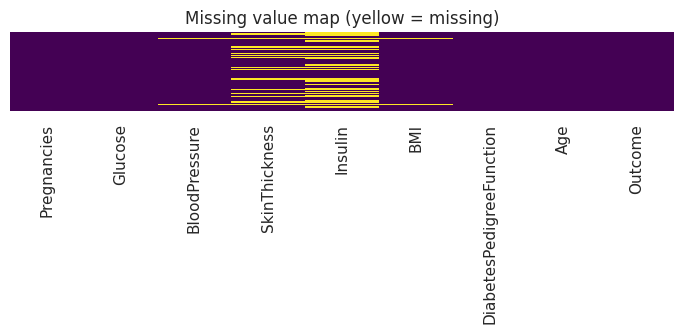

In [5]:
plt.figure(figsize=(7,3.5))
sns.heatmap(df_clean.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing value map (yellow = missing)')
plt.tight_layout(); plt.savefig('../results/01_missing_map.png', dpi=150); plt.show()

Insulin (~49 % missing) and SkinThickness (~30 %) have a lot of missing data. We keep them because dropping half the rows would waste data, and we **impute with the median**. The median is preferred over the mean because these features are skewed and have outliers (shown next).

> **Data-leakage rule:** the imputation values must be computed on the **training data only**. So we do the actual imputation inside a `Pipeline` after the train-test split (Section 5).

### 2.2 Outlier detection with the IQR method

IQR rule: a point is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`, where `IQR = Q3 - Q1`.

In [6]:
feat = [c for c in cols if c != 'Outcome']
rows = []
for c in feat:
    s = df_clean[c].dropna()
    q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    n = ((s<lo)|(s>hi)).sum()
    rows.append([c, round(q1,2), round(q3,2), round(lo,2), round(hi,2), n, round(100*n/len(s),1)])
outl = pd.DataFrame(rows, columns=['Feature','Q1','Q3','Lower fence','Upper fence','#Outliers','%'])
RESULTS['outliers'] = {r[0]: int(r[5]) for r in rows}
outl

,Feature,Q1,Q3,Lower fence,Upper fence,#Outliers,%
0,Pregnancies,1.00,6.00,-6.50,13.50,4,0.5
1,Glucose,99.00,141.00,36.00,204.00,0,0.0
2,BloodPressure,64.00,80.00,40.00,104.00,14,1.9
3,SkinThickness,22.00,36.00,1.00,57.00,3,0.6
4,Insulin,76.25,190.00,-94.38,360.62,24,6.1
5,BMI,27.50,36.60,13.85,50.25,8,1.1
6,DiabetesPedigreeFunction,0.24,0.63,-0.33,1.20,29,3.8
7,Age,24.00,41.00,-1.50,66.50,9,1.2


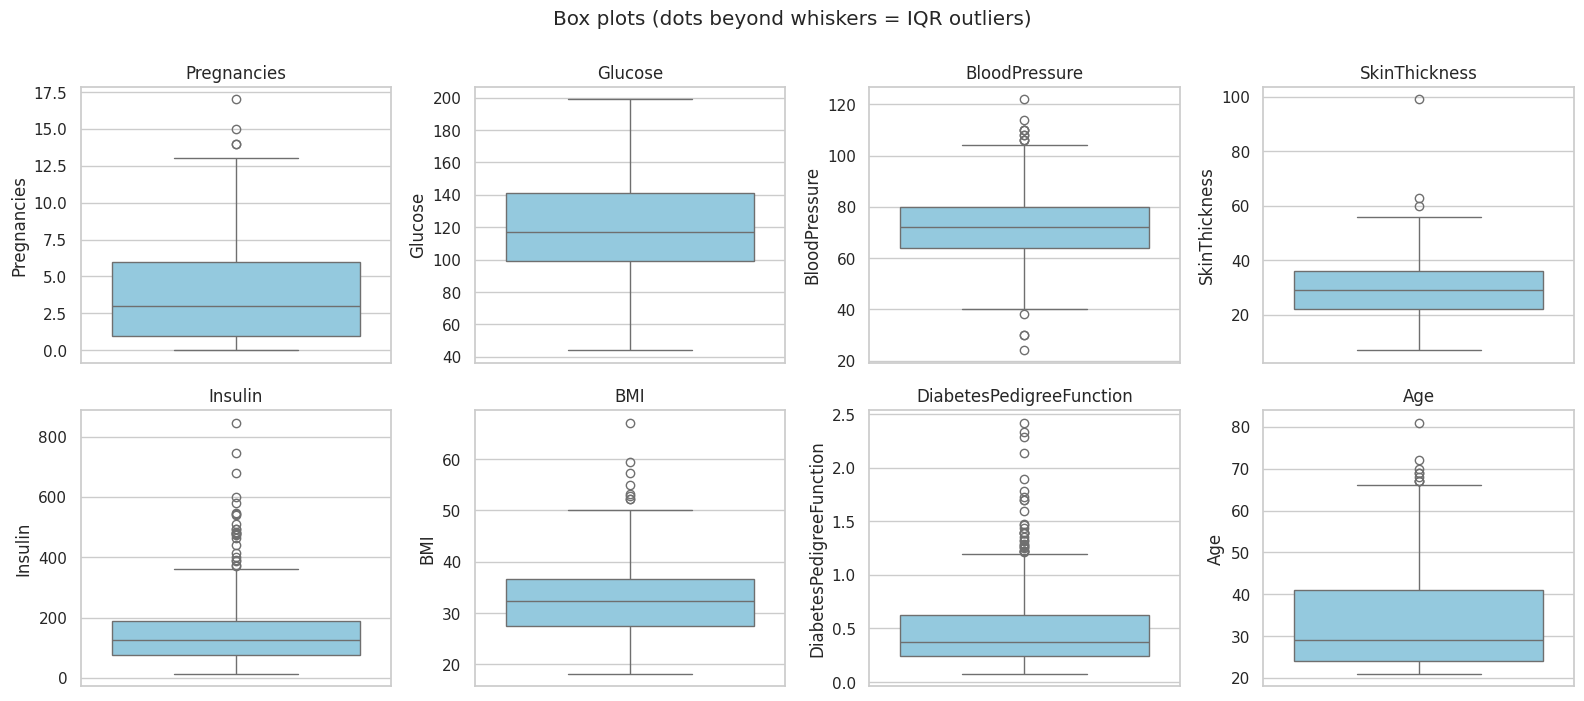

In [7]:
fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, c in zip(axes.ravel(), feat):
    sns.boxplot(y=df_clean[c], ax=ax, color='skyblue'); ax.set_title(c)
plt.suptitle('Box plots (dots beyond whiskers = IQR outliers)', y=1.0)
plt.tight_layout(); plt.savefig('../results/02_boxplots.png', dpi=150); plt.show()

**Decision:** Insulin, SkinThickness, DiabetesPedigreeFunction, etc. have outliers, but these are *genuine* extreme medical readings, not typing errors. Deleting them would throw away real patients (and mostly the high-risk ones). So we **keep them** and make the pipeline robust to them: median imputation, plus standard scaling. (Logistic regression and LDA are somewhat sensitive to outliers, which we mention in the limitations.)

## 3. Exploratory data analysis (EDA)

### 3.1 Class balance

Outcome
0    500
1    268
Name: count, dtype: int64 
 Outcome
0    65.1
1    34.9
Name: count, dtype: float64


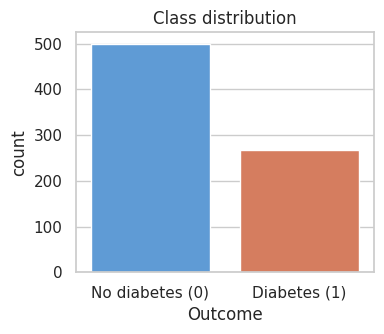

In [8]:
vc = df['Outcome'].value_counts()
print(vc, '\n', (vc/len(df)*100).round(1))
RESULTS['class_counts'] = {int(k): int(v) for k,v in vc.items()}
plt.figure(figsize=(4,3.5)); sns.countplot(x='Outcome', data=df, palette=['#4c9be8','#e8734c'])
plt.xticks([0,1],['No diabetes (0)','Diabetes (1)']); plt.title('Class distribution')
plt.tight_layout(); plt.savefig('../results/03_class_balance.png', dpi=150); plt.show()

About 65 % of patients are non-diabetic. This is **mildly imbalanced**. A silly model that always says "no diabetes" would already be ~65 % accurate, so **accuracy alone is misleading** and we will also use recall, F1 and AUC.

### 3.2 Distributions by class (histograms)

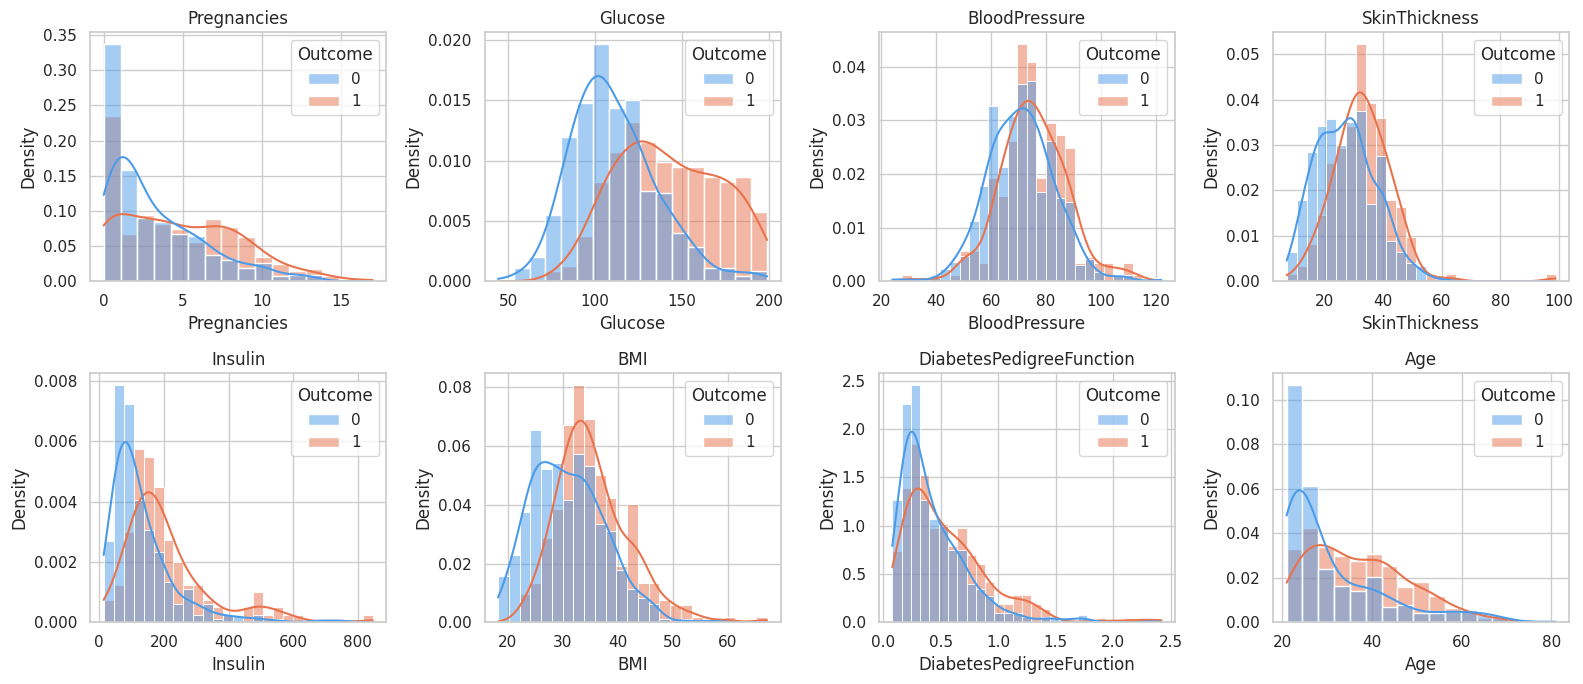

Skewness:
Pregnancies                 0.90
Glucose                     0.53
BloodPressure               0.13
SkinThickness               0.69
Insulin                     2.17
BMI                         0.59
DiabetesPedigreeFunction    1.92
Age                         1.13
dtype: float64


In [9]:
fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, c in zip(axes.ravel(), feat):
    sns.histplot(data=df_clean, x=c, hue='Outcome', kde=True, ax=ax, palette=['#4c9be8','#e8734c'], stat='density', common_norm=False)
    ax.set_title(c)
plt.tight_layout(); plt.savefig('../results/04_histograms.png', dpi=150); plt.show()
print('Skewness:'); print(df_clean[feat].skew().round(2))

Glucose separates the two classes best: the diabetic distribution (orange) is shifted to the right. Age, Insulin and BMI also shift. Many features are right-skewed (especially Insulin, DiabetesPedigreeFunction and Age).

### 3.3 Correlation heatmap

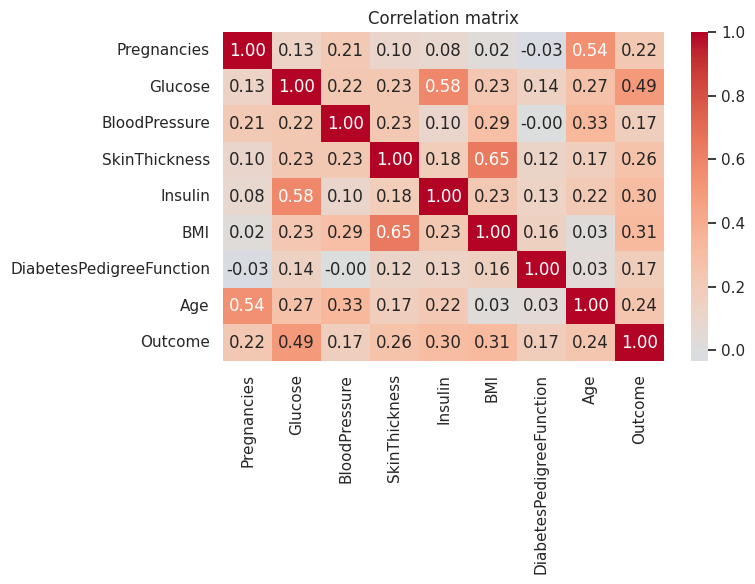

Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64

In [10]:
plt.figure(figsize=(8,6))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('../results/05_correlation.png', dpi=150); plt.show()
RESULTS['corr_with_outcome'] = corr['Outcome'].drop('Outcome').round(3).sort_values(ascending=False).to_dict()
corr['Outcome'].drop('Outcome').sort_values(ascending=False)

Glucose has the strongest correlation with Outcome (about 0.50), followed by BMI (0.31) and Insulin (0.30). Among the features themselves, the strongest pairs are SkinThickness-BMI (0.65), Glucose-Insulin (0.58) and Pregnancies-Age (0.54). None exceeds 0.8, so serious multicollinearity is not a worry.

### 3.4 Scatter plot of the two strongest predictors

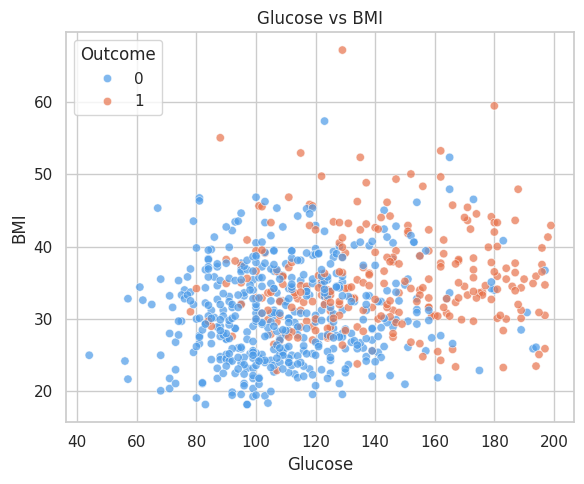

In [11]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df_clean, x='Glucose', y='BMI', hue='Outcome', palette=['#4c9be8','#e8734c'], alpha=.7)
plt.title('Glucose vs BMI'); plt.tight_layout(); plt.savefig('../results/06_scatter.png', dpi=150); plt.show()

## 4. Feature engineering and feature selection

### 4.1 Feature engineering
We create two new features and later test whether they actually help (we do not assume they do):
- `Glucose_BMI` = Glucose x BMI (captures a combined metabolic-risk effect)
- `Age_Preg` = Pregnancies / Age (pregnancy rate relative to age)

In [12]:
df_fe = df_clean.copy()
df_fe['Glucose_BMI'] = df_fe['Glucose'] * df_fe['BMI']
df_fe['Age_Preg'] = df_fe['Pregnancies'] / df_fe['Age']
base_feats = feat
fe_feats = feat + ['Glucose_BMI','Age_Preg']

### 4.2 Feature selection (ANOVA F-score on training data)

In [13]:
from sklearn.feature_selection import f_classif
X_all = df_fe[fe_feats]; y_all = df_fe['Outcome']
X_tr_tmp, _, y_tr_tmp, _ = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=RS)
X_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_tr_tmp), columns=fe_feats)
F, p = f_classif(X_imp, y_tr_tmp)
fs = pd.DataFrame({'Feature': fe_feats, 'F-score': F.round(1), 'p-value': p}).sort_values('F-score', ascending=False)
fs['p-value'] = fs['p-value'].map(lambda v: f'{v:.2e}')
RESULTS['f_scores'] = {r.Feature: float(r._2) for r in fs.itertuples()}
fs

,Feature,F-score,p-value
8,Glucose_BMI,252.9,6.33e-48
1,Glucose,217.8,2.20e-42
5,BMI,74.2,6.08e-17
4,Insulin,39.4,6.58e-10
7,Age,37.6,1.54e-09
3,SkinThickness,35.5,4.23e-09
0,Pregnancies,27.7,1.94e-07
2,BloodPressure,21.3,4.80e-06
6,DiabetesPedigreeFunction,17.2,3.85e-05
9,Age_Preg,12.2,5.04e-04


Higher F-score means the feature separates the two classes better. The engineered `Glucose_BMI` ranks first and Glucose second (both far ahead of the rest), while `Age_Preg`, DiabetesPedigreeFunction and BloodPressure are the weakest. A high F-score does not guarantee a better model, because `Glucose_BMI` is just built from two existing features. We will check with cross-validation whether the engineered features and dropping weak features actually improve results.

## 5. Train-test split

In [14]:
X = df_fe[fe_feats]; y = df_fe['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Diabetic share  train: %.1f%%  test: %.1f%%' % (y_train.mean()*100, y_test.mean()*100))

Train: (614, 10)  Test: (154, 10)
Diabetic share  train: 34.9%  test: 35.1%


`stratify=y` keeps the class ratio the same in both sets. The test set is locked away and used **only once** at the end for the final evaluation.

## 6. Does feature engineering / selection help? (5-fold cross-validation on training data)
We compare logistic regression on three feature sets.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
def make_pipe(model):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', model)])

sets = {
  'Original 8 features': base_feats,
  'Original + engineered (10)': fe_feats,
  'Top-6 by F-score': list(fs['Feature'].head(6)),
}
rows = []
for name, fl in sets.items():
    s = cross_val_score(make_pipe(LogisticRegression(max_iter=1000)), X_train[fl], y_train, cv=skf, scoring='roc_auc')
    rows.append([name, len(fl), s.mean().round(4), s.std().round(4)])
fs_cmp = pd.DataFrame(rows, columns=['Feature set','#features','CV AUC mean','CV AUC std'])
RESULTS['feature_set_cv'] = fs_cmp.set_index('Feature set')['CV AUC mean'].to_dict()
fs_cmp

,Feature set,#features,CV AUC mean,CV AUC std
0,Original 8 features,8,0.8434,0.0185
1,Original + engineered (10),10,0.8422,0.0180
2,Top-6 by F-score,6,0.8306,0.0254


In [16]:
best_set = fs_cmp.sort_values('CV AUC mean', ascending=False).iloc[0]['Feature set']
FEATS = sets[best_set]
RESULTS['chosen_feature_set'] = best_set
print('Chosen feature set:', best_set); print(FEATS)

Chosen feature set: Original 8 features
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


We choose the feature set with the best cross-validated AUC. The original 8 features win (0.843 vs 0.842 vs 0.831): the engineered features add nothing, because logistic regression can already combine Glucose and BMI itself. When differences are tiny, the simpler set is better (principle of parsimony). Reporting a feature-engineering idea that did *not* help is a perfectly valid research finding.

## 7. Models
### 7.1 Theory in one place
| Model | Idea | Decision boundary | Assumption |
|---|---|---|---|
| **Logistic regression** | Models `P(y=1|x) = 1/(1+e^-(b0+b.x))` directly; coefficients found by maximum likelihood | Linear | No distribution assumed for x |
| **LDA** | Models `P(x|class)` as Gaussian, **same covariance** for both classes, then uses Bayes' rule | Linear | Gaussian classes + equal covariance |
| **QDA** | Same as LDA but **each class has its own covariance** | Quadratic (curved) | Gaussian classes; more parameters |

Baseline: a `DummyClassifier` that always predicts the majority class.

In [17]:
models = {
  'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
  'Logistic Regression': LogisticRegression(max_iter=1000),
  'LDA': LinearDiscriminantAnalysis(),
  'QDA': QuadraticDiscriminantAnalysis(),
}
scoring = ['accuracy','precision','recall','f1','roc_auc']
cv_rows = []
for name, m in models.items():
    r = cross_validate(make_pipe(m), X_train[FEATS], y_train, cv=skf, scoring=scoring)
    cv_rows.append([name] + [r[f'test_{s}'].mean().round(3) for s in scoring])
cv_df = pd.DataFrame(cv_rows, columns=['Model','Accuracy','Precision','Recall','F1','AUC'])
RESULTS['cv_table'] = cv_df.set_index('Model').to_dict('index')
cv_df

,Model,Accuracy,Precision,Recall,F1,AUC
0,Baseline (majority),0.651,0.000,0.000,0.000,0.500
1,Logistic Regression,0.788,0.764,0.575,0.655,0.843
2,LDA,0.787,0.758,0.575,0.653,0.843
3,QDA,0.754,0.681,0.561,0.613,0.820


These are 5-fold cross-validation scores on the training set: the data is split into 5 parts, each part is used once as a validation set, and the 5 scores are averaged. This is far more reliable than a single split.

## 8. Hyperparameter tuning (Grid Search with cross-validation)

In [18]:
grids = {
  'Logistic Regression': (LogisticRegression(max_iter=2000), {'clf__C':[0.01,0.1,1,10,100], 'clf__penalty':['l2']}),
  'LDA': (LinearDiscriminantAnalysis(), {'clf__solver':['lsqr'], 'clf__shrinkage':[None,0.1,0.3,0.5,'auto']}),
  'QDA': (QuadraticDiscriminantAnalysis(), {'clf__reg_param':[0.0,0.1,0.3,0.5,0.7,0.9]}),
}
best_models, gs_rows = {}, []
for name,(m,g) in grids.items():
    gs = GridSearchCV(make_pipe(m), g, cv=skf, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_train[FEATS], y_train)
    best_models[name] = gs.best_estimator_
    gs_rows.append([name, str(gs.best_params_), round(gs.best_score_,4)])
gs_df = pd.DataFrame(gs_rows, columns=['Model','Best parameters','Best CV AUC'])
RESULTS['grid_search'] = {r[0]: {'params': r[1], 'cv_auc': r[2]} for r in gs_rows}
gs_df

,Model,Best parameters,Best CV AUC
0,Logistic Regression,"{'clf__C': 0.1, 'clf__penalty': 'l2'}",0.8444
1,LDA,"{'clf__shrinkage': 0.3, 'clf__solver': 'lsqr'}",0.8445
2,QDA,{'clf__reg_param': 0.7},0.8320


- Logistic regression: `C` is the inverse of regularisation strength (small C = strong regularisation).
- LDA: `shrinkage` stabilises the covariance estimate.
- QDA: `reg_param` blends each class covariance toward identity, reducing the overfitting risk that comes from QDA's many parameters.

## 9. Final evaluation on the untouched test set

In [19]:
def evaluate(model, Xt, yt):
    pred = model.predict(Xt); prob = model.predict_proba(Xt)[:,1]
    return dict(Accuracy=accuracy_score(yt,pred), Precision=precision_score(yt,pred), Recall=recall_score(yt,pred),
                F1=f1_score(yt,pred), AUC=roc_auc_score(yt,prob),
                RMSE=np.sqrt(mean_squared_error(yt,prob)), MAE=mean_absolute_error(yt,prob))
base = make_pipe(DummyClassifier(strategy='most_frequent')).fit(X_train[FEATS], y_train)
final = {'Baseline (majority)': base, **best_models}
test_res = {n: evaluate(m, X_test[FEATS], y_test) for n,m in final.items()}
test_df = pd.DataFrame(test_res).T.round(3)
RESULTS['test_table'] = test_df.to_dict('index')
test_df

,Accuracy,Precision,Recall,F1,AUC,RMSE,MAE
Baseline (majority),0.649,0.000,0.000,0.000,0.500,0.592,0.351
Logistic Regression,0.688,0.565,0.481,0.520,0.810,0.417,0.327
LDA,0.701,0.580,0.537,0.558,0.804,0.426,0.314
QDA,0.721,0.604,0.593,0.598,0.780,0.445,0.319


`RMSE` and `MAE` here are computed between the predicted **probability** and the true 0/1 label. (Strictly, RMSE and MAE are regression metrics; for classification, accuracy/F1/AUC are the main metrics. They are shown because they are in the syllabus.)

### 9.1 Confusion matrices

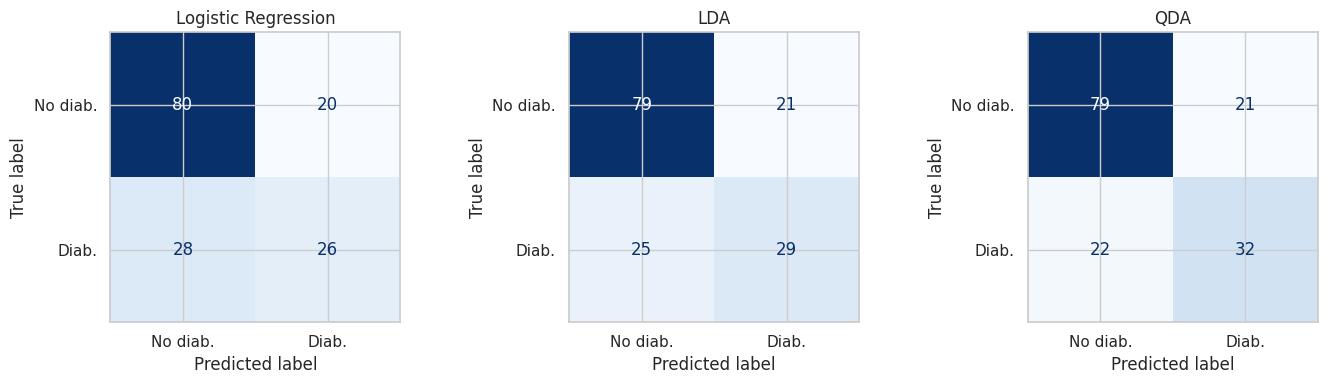

In [20]:
fig, axes = plt.subplots(1,3, figsize=(14,4))
for ax,(n,m) in zip(axes, [(k,v) for k,v in final.items() if k!='Baseline (majority)']):
    ConfusionMatrixDisplay.from_estimator(m, X_test[FEATS], y_test, ax=ax, cmap='Blues', display_labels=['No diab.','Diab.'], colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.savefig('../results/07_confusion.png', dpi=150); plt.show()
RESULTS['confusion'] = {n: confusion_matrix(y_test, m.predict(X_test[FEATS])).tolist() for n,m in final.items() if n!='Baseline (majority)'}

Reading a confusion matrix (rows = actual, columns = predicted): top-left = True Negatives, top-right = False Positives, bottom-left = **False Negatives** (diabetic patients we missed, the costly error in medicine), bottom-right = True Positives.

### 9.2 ROC curves

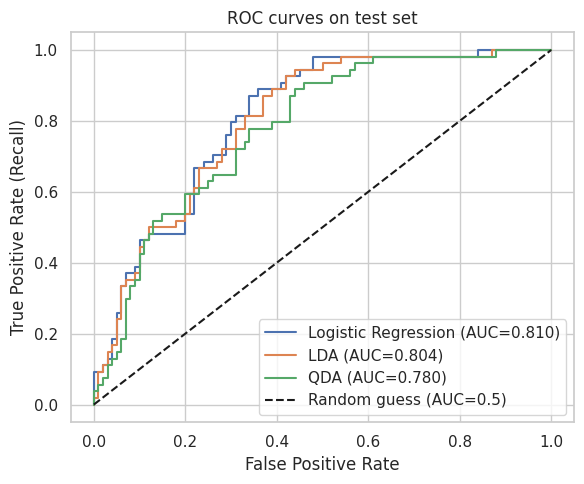

In [21]:
plt.figure(figsize=(6,5))
for n,m in final.items():
    if n=='Baseline (majority)': continue
    fpr,tpr,_ = roc_curve(y_test, m.predict_proba(X_test[FEATS])[:,1])
    plt.plot(fpr,tpr,label=f"{n} (AUC={test_res[n]['AUC']:.3f})")
plt.plot([0,1],[0,1],'k--',label='Random guess (AUC=0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)'); plt.title('ROC curves on test set'); plt.legend()
plt.tight_layout(); plt.savefig('../results/08_roc.png', dpi=150); plt.show()

## 10. Overfitting / underfitting check

In [22]:
rows=[]
for n,m in best_models.items():
    tr = roc_auc_score(y_train, m.predict_proba(X_train[FEATS])[:,1]); te = test_res[n]['AUC']
    rows.append([n, round(tr,3), round(te,3), round(tr-te,3)])
of = pd.DataFrame(rows, columns=['Model','Train AUC','Test AUC','Gap'])
RESULTS['overfit'] = of.set_index('Model').to_dict('index')
of

,Model,Train AUC,Test AUC,Gap
0,Logistic Regression,0.851,0.810,0.041
1,LDA,0.850,0.804,0.046
2,QDA,0.839,0.780,0.058


A large gap (train much higher than test) indicates **overfitting** (high variance); low scores on both indicate **underfitting** (high bias). A small gap with decent scores means a good fit. How we controlled overfitting: cross-validation, regularisation (C, shrinkage, reg_param), a held-out test set, and a modest number of features.

## 11. Interpreting the models

### 11.1 Logistic regression: coefficients as odds ratios

In [23]:
lr = best_models['Logistic Regression'].named_steps['clf']
coef = pd.DataFrame({'Feature': FEATS, 'Coefficient (scaled)': lr.coef_[0].round(3), 'Odds ratio': np.exp(lr.coef_[0]).round(3)}).sort_values('Coefficient (scaled)', ascending=False)
RESULTS['lr_coef'] = coef.set_index('Feature').to_dict('index')
coef

,Feature,Coefficient (scaled),Odds ratio
1,Glucose,1.019,2.770
5,BMI,0.580,1.786
0,Pregnancies,0.322,1.380
6,DiabetesPedigreeFunction,0.210,1.234
7,Age,0.158,1.171
3,SkinThickness,0.067,1.070
4,Insulin,-0.003,0.997
2,BloodPressure,-0.004,0.996


Because features are standardised, each coefficient is the change in **log-odds** for a **1 standard-deviation** increase in that feature; `Odds ratio = e^coefficient`. For example, an odds ratio of 1.8 for Glucose means one SD more glucose multiplies the odds of diabetes by about 1.8 (other features held fixed).

### 11.2 Is the LDA 'equal covariance' assumption reasonable?

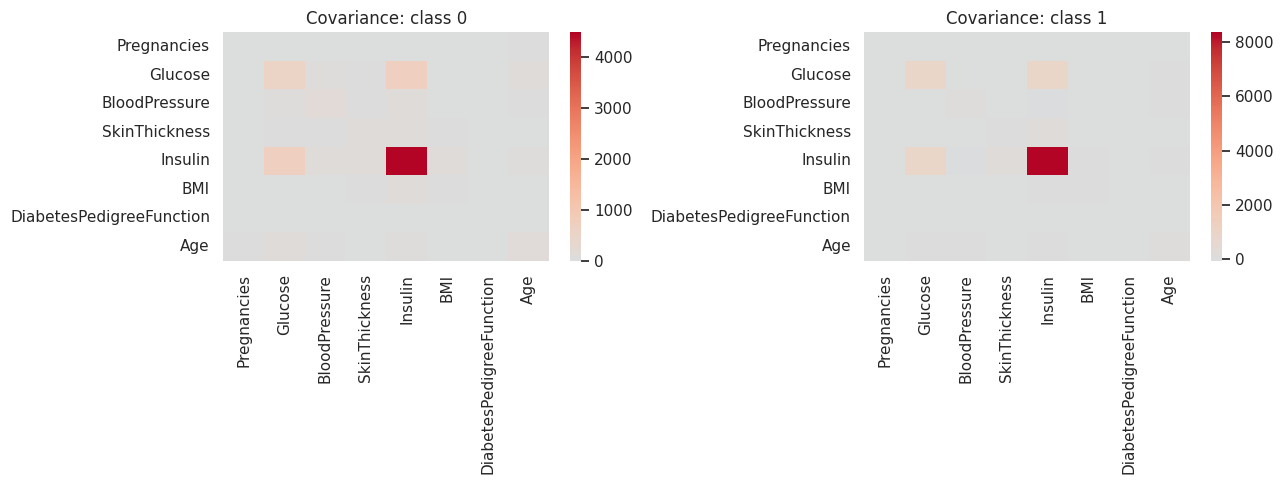

Frobenius norm of difference / norm of class-0 cov: 0.84


In [24]:
Xi = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train[FEATS]), columns=FEATS, index=X_train.index)
c0 = np.cov(Xi[y_train==0].T); c1 = np.cov(Xi[y_train==1].T)
fig, axes = plt.subplots(1,2, figsize=(13,5))
sns.heatmap(pd.DataFrame(c0,index=FEATS,columns=FEATS), ax=axes[0], cmap='coolwarm', center=0); axes[0].set_title('Covariance: class 0')
sns.heatmap(pd.DataFrame(c1,index=FEATS,columns=FEATS), ax=axes[1], cmap='coolwarm', center=0); axes[1].set_title('Covariance: class 1')
plt.tight_layout(); plt.savefig('../results/09_covariances.png', dpi=150); plt.show()
print('Frobenius norm of difference / norm of class-0 cov: %.2f' % (np.linalg.norm(c1-c0)/np.linalg.norm(c0)))

If the two covariance matrices look quite different, QDA's assumption fits better; if similar, LDA is enough. Here they differ somewhat (e.g. diabetic patients have larger variance in Glucose and Insulin), but QDA must estimate twice as many covariance parameters from only ~600 training samples, which makes it less stable. This is consistent with QDA having the lowest cross-validated AUC.

## 12. Threshold tuning (recall vs precision trade-off)

In [25]:
m = best_models['Logistic Regression']
prob = m.predict_proba(X_test[FEATS])[:,1]
rows=[]
for t in [0.3,0.4,0.5,0.6]:
    p = (prob>=t).astype(int)
    rows.append([t, round(accuracy_score(y_test,p),3), round(precision_score(y_test,p),3), round(recall_score(y_test,p),3), round(f1_score(y_test,p),3)])
thr = pd.DataFrame(rows, columns=['Threshold','Accuracy','Precision','Recall','F1'])
RESULTS['threshold'] = thr.set_index('Threshold').to_dict('index')
thr

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.727,0.579,0.815,0.677
1,0.4,0.734,0.614,0.648,0.631
2,0.5,0.688,0.565,0.481,0.520
3,0.6,0.747,0.714,0.463,0.562


Lowering the threshold from 0.5 to 0.3 catches more diabetic patients (higher recall) but raises false alarms (lower precision). For medical screening, missing a sick patient is usually worse than a false alarm, so a lower threshold can be justified.

## 13. Prediction for a new patient

In [26]:
new = pd.DataFrame([{'Pregnancies':3,'Glucose':150,'BloodPressure':76,'SkinThickness':30,'Insulin':150,'BMI':33.0,
                     'DiabetesPedigreeFunction':0.5,'Age':45}])
new['Glucose_BMI']=new['Glucose']*new['BMI']; new['Age_Preg']=new['Pregnancies']/new['Age']
for n,m in best_models.items():
    print(f"{n:20s}: P(diabetes) = {m.predict_proba(new[FEATS])[0,1]:.3f}  ->  {'Diabetic' if m.predict(new[FEATS])[0] else 'Non-diabetic'}")

Logistic Regression : P(diabetes) = 0.566  ->  Diabetic
LDA                 : P(diabetes) = 0.611  ->  Diabetic
QDA                 : P(diabetes) = 0.566  ->  Diabetic


## 14. Conclusions, limitations and ethics
**Conclusions**
- Glucose is the dominant predictor; BMI, Age and Pregnancies add useful signal.
- Handling hidden zeros as missing values was essential data preparation.
- All three models beat the majority-class baseline in AUC (about 0.78-0.81 vs 0.50). Logistic Regression and LDA perform almost identically (CV AUC 0.844 vs 0.845), as expected, since both give linear boundaries.
- QDA is the weakest on cross-validated AUC (0.832), but on the 154-patient test set it has the highest accuracy and recall. With such a small test set, a difference of a few patients changes these numbers, so we do not claim QDA is truly better. The more reliable cross-validation evidence favours the simpler linear models.
- Lowering the decision threshold from 0.5 to 0.3 raises recall from 0.48 to 0.82 at the cost of precision, which may suit screening.
- Accuracy alone is not enough because of class imbalance; recall, F1 and AUC give the full picture.

**Limitations**
- Small dataset (768 rows, only women of Pima heritage, aged 21+), so results may not generalise to other populations.
- Heavy imputation for Insulin (~49 % missing) and SkinThickness (~30 %).
- LDA/QDA assume Gaussian features, which is only approximately true here (skewed features).
- No external validation dataset.

**Ethical considerations**
- A false negative means a sick person is told they are healthy, so the model should only support a doctor and never replace clinical diagnosis.
- Bias: training data come from one ethnic group; applying the model to others could be unfair or inaccurate.
- Privacy: medical data is sensitive and needs consent and anonymisation.

**Future work:** try more models (e.g. regularised, tree-based), use better imputation (KNN/iterative), collect more data, calibrate probabilities.

In [27]:
with open('../results/metrics.json','w') as f: json.dump(RESULTS, f, indent=2, default=str)
print('Saved metrics.json')

Saved metrics.json
